<a href="https://colab.research.google.com/github/AlvinManoj05/Parallel_project_Computer_Vision/blob/main/Parallel_Project__computerVision_PneumoniaDetection.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

01_Dataset_Exploration_and_Preprocessing-Ananthika

Import Libraries

In [11]:

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import random
from PIL import Image
from sklearn.model_selection import train_test_split
import tensorflow as tf
from google.colab import drive


In [12]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [13]:
drive.mount('/content/drive')


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [14]:
dataset_path = "/content/drive/MyDrive/AI-ML/Datasets/xray_dataset_covid19"

print("Dataset exists:", os.path.exists(dataset_path))
print("Available folders:", os.listdir(dataset_path))


Dataset exists: True
Available folders: ['single prediction', 'test', 'train']


In [15]:
#Count the images

classes = ["NORMAL", "PNEUMONIA"]

for split in ["train", "test"]:
    print(f"\n{split.upper()} DATASET")

    for class_name in classes:
        folder = os.path.join(dataset_path, split, class_name)

        images = [
            file for file in os.listdir(folder)
            if file.lower().endswith((".jpg", ".jpeg", ".png"))
        ]

        print(f"{class_name}: {len(images)} images")



TRAIN DATASET
NORMAL: 74 images
PNEUMONIA: 74 images

TEST DATASET
NORMAL: 20 images
PNEUMONIA: 20 images


Dataset Exploration – Image Visualization

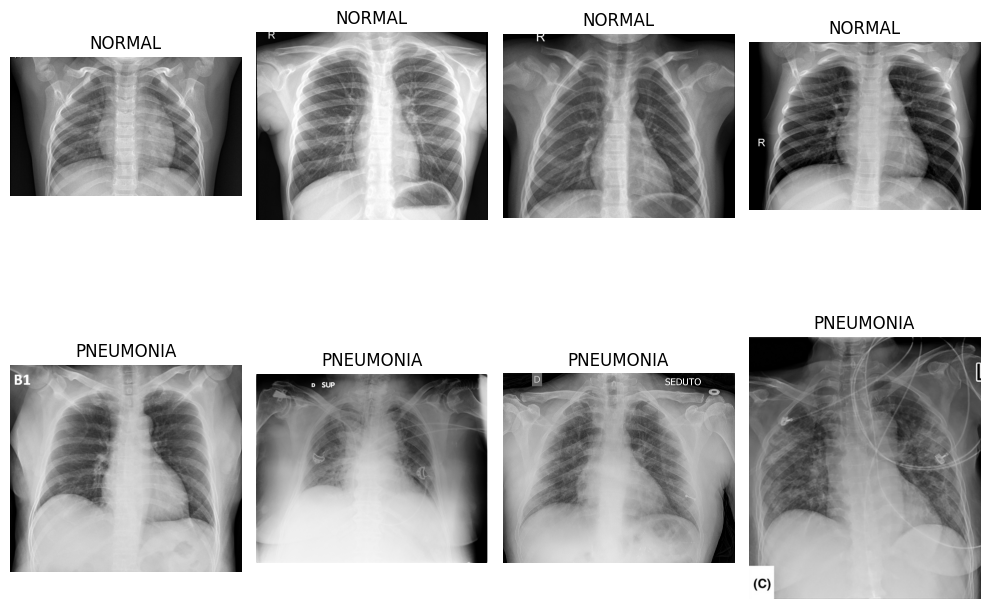

In [16]:
#Display NORMAL and PNEUMONIA images
classes = ["NORMAL", "PNEUMONIA"]

plt.figure(figsize=(10, 8))

for i, class_name in enumerate(classes):
    folder = os.path.join(dataset_path, "train", class_name)

    image_files = [
        f for f in os.listdir(folder)
        if f.lower().endswith((".jpg", ".jpeg", ".png"))
    ]

    sample_images = random.sample(image_files, min(4, len(image_files)))

    for j, image_name in enumerate(sample_images):
        image_path = os.path.join(folder, image_name)
        image = mpimg.imread(image_path)

        plt.subplot(2, 4, i * 4 + j + 1)
        plt.imshow(image, cmap="gray")
        plt.title(class_name)
        plt.axis("off")

plt.tight_layout()
plt.show()


In [17]:
#Image dimensions and formats
image_data = []

classes = ["NORMAL", "PNEUMONIA"]

for class_name in classes:
    folder = os.path.join(dataset_path, "train", class_name)

    for filename in os.listdir(folder):
        image_path = os.path.join(folder, filename)

        try:
            with Image.open(image_path) as img:
                image_data.append({
                    "Class": class_name,
                    "Filename": filename,
                    "Width": img.width,
                    "Height": img.height,
                    "Format": img.format,
                    "Mode": img.mode
                })

        except Exception as e:
            print("Error:", filename, e)

df = pd.DataFrame(image_data)

print("Total images inspected:", len(df))
print("\nImage dimensions:")
print(df[["Width", "Height"]].describe())

print("\nImage formats:")
print(df["Format"].value_counts())

print("\nImage modes:")
print(df["Mode"].value_counts())


Total images inspected: 148

Image dimensions:
             Width       Height
count   148.000000   148.000000
mean   1697.527027  1385.479730
std     767.623698   693.882888
min     255.000000   237.000000
25%    1246.750000   875.500000
50%    1790.500000  1376.500000
75%    2060.250000  1757.250000
max    4248.000000  4095.000000

Image formats:
Format
JPEG    136
PNG      12
Name: count, dtype: int64

Image modes:
Mode
L       81
RGB     56
RGBA    11
Name: count, dtype: int64


In [18]:
#Check for corrupted images
corrupted_images = []
checked_images = 0

for split in ["train", "test"]:
    for class_name in classes:

        folder = os.path.join(dataset_path, split, class_name)

        for filename in os.listdir(folder):
            image_path = os.path.join(folder, filename)

            try:
                with Image.open(image_path) as img:
                    img.verify()

                checked_images += 1

            except Exception:
                corrupted_images.append(image_path)

print("Images checked:", checked_images)
print("Corrupted images:", len(corrupted_images))
print("\nCorrupted file paths:")
print(corrupted_images)


Images checked: 188
Corrupted images: 0

Corrupted file paths:
[]


Train-validation split

In [19]:

image_paths = []
labels = []

class_names = ["NORMAL", "PNEUMONIA"]

for label, class_name in enumerate(class_names):

    folder = os.path.join(dataset_path, "train", class_name)

    for filename in os.listdir(folder):

        if filename.lower().endswith((".jpg", ".jpeg", ".png")):

            image_paths.append(os.path.join(folder, filename))
            labels.append(label)

# Split training data into training and validation
X_train, X_val, y_train, y_val = train_test_split(
    image_paths,
    labels,
    test_size=0.20,
    random_state=42,
    stratify=labels
)

print("Training images:", len(X_train))
print("Validation images:", len(X_val))

print("\nTraining class distribution:")
for label, class_name in enumerate(class_names):
    print(class_name, ":", y_train.count(label))

print("\nValidation class distribution:")
for label, class_name in enumerate(class_names):
    print(class_name, ":", y_val.count(label))


Training images: 118
Validation images: 30

Training class distribution:
NORMAL : 59
PNEUMONIA : 59

Validation class distribution:
NORMAL : 15
PNEUMONIA : 15


Image resizing and normalization

In [20]:
IMG_SIZE = 224

def preprocess_images(image_paths):
    images = []

    for path in image_paths:
        img = Image.open(path).convert("L")
        img = img.resize((IMG_SIZE, IMG_SIZE))

        img_array = np.array(img, dtype=np.float32) / 255.0

        images.append(img_array)

    images = np.array(images)
    images = np.expand_dims(images, axis=-1)

    return images

# Preprocess training and validation images
X_train_processed = preprocess_images(X_train)
X_val_processed = preprocess_images(X_val)

# Convert labels into NumPy arrays
y_train = np.array(y_train, dtype=np.float32)
y_val = np.array(y_val, dtype=np.float32)

print("Training shape:", X_train_processed.shape)
print("Validation shape:", X_val_processed.shape)

print("Minimum pixel value:", X_train_processed.min())
print("Maximum pixel value:", X_train_processed.max())


Training shape: (118, 224, 224, 1)
Validation shape: (30, 224, 224, 1)
Minimum pixel value: 0.0
Maximum pixel value: 1.0


Visualize preprocessed images

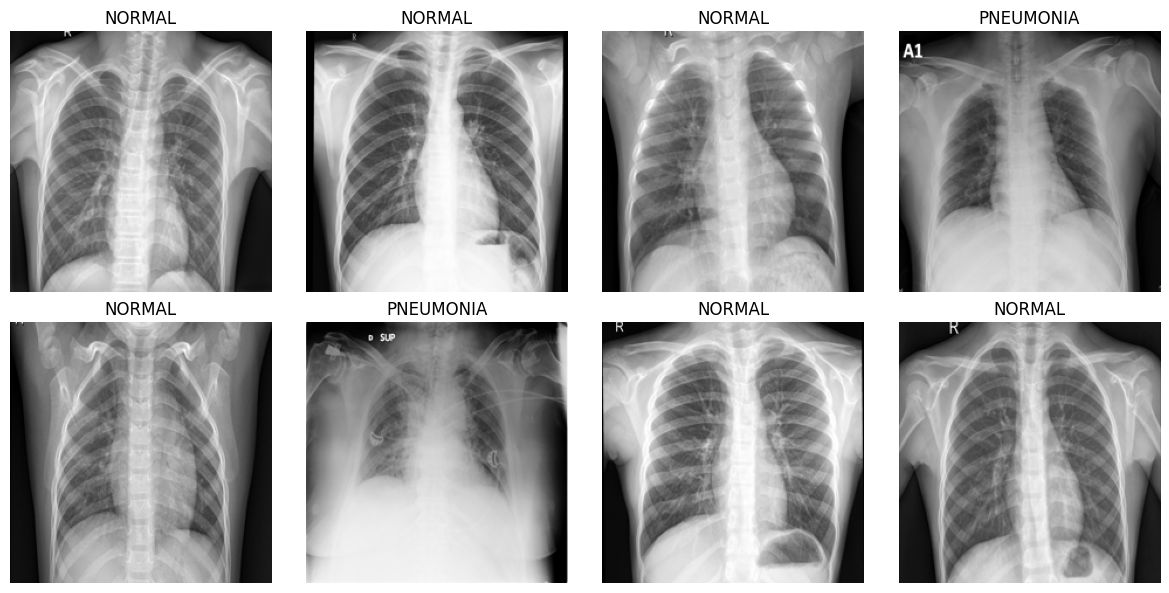

In [21]:
plt.figure(figsize=(12, 6))

for i in range(8):
    plt.subplot(2, 4, i + 1)

    plt.imshow(X_train_processed[i].squeeze(), cmap="gray")

    label = class_names[int(y_train[i])]
    plt.title(label)

    plt.axis("off")

plt.tight_layout()
plt.show()


Preprocess test images

In [22]:
test_paths = []
test_labels = []

class_names = ["NORMAL", "PNEUMONIA"]

for label, class_name in enumerate(class_names):

    folder = os.path.join(dataset_path, "test", class_name)

    for filename in os.listdir(folder):

        if filename.lower().endswith((".jpg", ".jpeg", ".png")):

            test_paths.append(os.path.join(folder, filename))
            test_labels.append(label)

# Preprocess test images
X_test_processed = preprocess_images(test_paths)

y_test = np.array(test_labels, dtype=np.float32)

print("Test images:", len(X_test_processed))
print("Test shape:", X_test_processed.shape)

print("\nTest class distribution:")

for i, name in enumerate(class_names):
    print(name, ":", np.sum(y_test == i))


Test images: 40
Test shape: (40, 224, 224, 1)

Test class distribution:
NORMAL : 20
PNEUMONIA : 20


Verify all datasets

In [23]:
print("FINAL DATASET SHAPES")

print("Training:", X_train_processed.shape)
print("Validation:", X_val_processed.shape)
print("Testing:", X_test_processed.shape)

print("\nLabel shapes")

print("Training labels:", y_train.shape)
print("Validation labels:", y_val.shape)
print("Testing labels:", y_test.shape)


FINAL DATASET SHAPES
Training: (118, 224, 224, 1)
Validation: (30, 224, 224, 1)
Testing: (40, 224, 224, 1)

Label shapes
Training labels: (118,)
Validation labels: (30,)
Testing labels: (40,)


Convert images into TensorFlow datasets

In [24]:
BATCH_SIZE = 16

# Training dataset
train_dataset = tf.data.Dataset.from_tensor_slices(
    (X_train_processed, y_train)
)

train_dataset = (
    train_dataset
    .shuffle(buffer_size=len(X_train_processed), seed=42)
    .batch(BATCH_SIZE)
    .prefetch(tf.data.AUTOTUNE)
)

# Validation dataset
val_dataset = tf.data.Dataset.from_tensor_slices(
    (X_val_processed, y_val)
)

val_dataset = (
    val_dataset
    .batch(BATCH_SIZE)
    .prefetch(tf.data.AUTOTUNE)
)

# Testing dataset
test_dataset = tf.data.Dataset.from_tensor_slices(
    (X_test_processed, y_test)
)

test_dataset = (
    test_dataset
    .batch(BATCH_SIZE)
    .prefetch(tf.data.AUTOTUNE)
)

print("TensorFlow datasets created successfully!")

print("Training batches:", len(train_dataset))
print("Validation batches:", len(val_dataset))
print("Testing batches:", len(test_dataset))


TensorFlow datasets created successfully!
Training batches: 8
Validation batches: 2
Testing batches: 3


In [25]:
for images, labels in train_dataset.take(1):

    print("Image batch shape:", images.shape)
    print("Label batch shape:", labels.shape)
    print("Image data type:", images.dtype)
    print("Minimum pixel value:", tf.reduce_min(images).numpy())
    print("Maximum pixel value:", tf.reduce_max(images).numpy())


Image batch shape: (16, 224, 224, 1)
Label batch shape: (16,)
Image data type: <dtype: 'float32'>
Minimum pixel value: 0.0
Maximum pixel value: 1.0


In [26]:
save_path = "/content/preprocessed_data"
os.makedirs(save_path, exist_ok=True)

np.save(save_path + "/X_train.npy", X_train_processed)
np.save(save_path + "/y_train.npy", y_train)
np.save(save_path + "/X_val.npy", X_val_processed)
np.save(save_path + "/y_val.npy", y_val)
np.save(save_path + "/X_test.npy", X_test_processed)
np.save(save_path + "/y_test.npy", y_test)

print("Saved inside Colab successfully!")

Saved inside Colab successfully!


##Model Development-CNN-Anjima



**Import libraries**


In [27]:
from tensorflow.keras import layers, models
from tensorflow.keras.applications import ResNet50
from tensorflow.keras.applications.resnet50 import preprocess_input
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)

In [28]:
#check input data
print("Training images:", X_train_processed.shape)
print("Validation images:", X_val_processed.shape)

print("Training labels:", y_train.shape)
print("Validation labels:", y_val.shape)

Training images: (118, 224, 224, 1)
Validation images: (30, 224, 224, 1)
Training labels: (118,)
Validation labels: (30,)


In [29]:
#check shape of test images and test labels
print("Test images:", X_test_processed.shape)
print("Test labels:", y_test.shape)

Test images: (40, 224, 224, 1)
Test labels: (40,)


**CNN Model**

In [30]:
cnn_model = models.Sequential([
layers.Input(shape=(224, 224, 1)),
layers.Conv2D(32, (3,3), activation='relu', padding='same'),
layers.MaxPooling2D(2,2),

layers.Conv2D(64, (3,3), activation='relu', padding='same'),
layers.MaxPooling2D(2,2),

layers.Conv2D(128, (3,3), activation='relu', padding='same'),
layers.MaxPooling2D(2,2),

layers.GlobalAveragePooling2D(),

layers.Dense(128, activation='relu'),

layers.Dropout(0.5),

layers.Dense(1, activation='sigmoid')])

cnn_model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_3 (Conv2D)               │ (None, 224, 224, 32)   │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 112, 112, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 56, 56, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 109,313 (427.00 KB)

 Trainable params: 109,313 (427.00 KB)

 Non-trainable params: 0 (0.00 B)

In [31]:
#compile the model
cnn_model.compile(optimizer='adam',loss='binary_crossentropy',metrics=[
        'accuracy',
        tf.keras.metrics.Precision(name='precision'),
        tf.keras.metrics.Recall(name='recall'),
        tf.keras.metrics.AUC(name='auc')])

In [32]:
#train the model
early_stop_cnn = EarlyStopping(
    monitor='val_loss',
    patience=5,
    restore_best_weights=True)
cnn_history = cnn_model.fit(
 X_train_processed,y_train,
validation_data=(X_val_processed, y_val),epochs=20,batch_size=16,callbacks=[early_stop_cnn])

Epoch 1/20
8/8 ━━━━━━━━━━━━━━━━━━━━ 40s 3s/step - accuracy: 0.4915 - auc: 0.4703 - loss: 0.7002 - precision: 0.3333 - recall: 0.0169 - val_accuracy: 0.5000 - val_auc: 0.4089 - val_loss: 0.6952 - val_precision: 0.0000e+00 - val_recall: 0.0000e+00
Epoch 2/20
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 50ms/step - accuracy: 0.4746 - auc: 0.4849 - loss: 0.6950 - precision: 0.2857 - recall: 0.0339 - val_accuracy: 0.5000 - val_auc: 0.4667 - val_loss: 0.6935 - val_precision: 0.0000e+00 - val_recall: 0.0000e+00
Epoch 3/20
8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 45ms/step - accuracy: 0.5339 - auc: 0.5902 - loss: 0.6885 - precision: 0.5417 - recall: 0.4407 - val_accuracy: 0.6333 - val_auc: 0.5000 - val_loss: 0.6923 - val_precision: 0.5833 - val_recall: 0.9333
Epoch 4/20
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 59ms/step - accuracy: 0.5169 - auc: 0.5628 - loss: 0.6897 - precision: 0.5238 - recall: 0.3729 - val_accuracy: 0.5000 - val_auc: 0.7067 - val_loss: 0.6913 - val_precision: 0.0000e+00 - val_recall: 0.0000e+00
Epoch 5/20
8/8 ━━━━━━

In [33]:
#save the model
cnn_model.save("custom_cnn.keras")

# finetuning cnn - dhevan


In [34]:
# ==========================================
# CUSTOM CNN FINE-TUNING
# ==========================================

# Load the saved baseline Custom CNN model
cnn_finetuned = tf.keras.models.load_model("custom_cnn.keras")

# Optional: Freeze the first convolutional block (Conv2D + MaxPooling2D)
# and fine-tune the deeper layers. Comment out these 2 lines to train all layers.
for layer in cnn_finetuned.layers[:2]:
    layer.trainable = False

# Recompile with a much lower learning rate for fine-tuning
cnn_finetuned.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.0001),
    loss="binary_crossentropy",
    metrics=[
        "accuracy",
        tf.keras.metrics.Precision(name="precision"),
        tf.keras.metrics.Recall(name="recall"),
        tf.keras.metrics.AUC(name="auc"),
    ],
)

cnn_finetuned.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_3 (Conv2D)               │ (None, 224, 224, 32)   │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 112, 112, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 56, 56, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 109,313 (427.00 KB)

 Trainable params: 108,993 (425.75 KB)

 Non-trainable params: 320 (1.25 KB)

In [35]:
early_stop_cnn_ft = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True,
)

reduce_lr_cnn_ft = ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=2,
    min_lr=1e-7,
)

cnn_finetune_history = cnn_finetuned.fit(
    X_train_processed,
    y_train,
    validation_data=(X_val_processed, y_val),
    epochs=15,
    batch_size=16,
    callbacks=[early_stop_cnn_ft, reduce_lr_cnn_ft],
)

# Save the fine-tuned Custom CNN
cnn_finetuned.save("custom_cnn_finetuned.keras")
print("Fine-tuned Custom CNN saved successfully!")

Epoch 1/15
8/8 ━━━━━━━━━━━━━━━━━━━━ 14s 1s/step - accuracy: 0.8305 - auc: 0.8763 - loss: 0.4400 - precision: 0.8095 - recall: 0.8644 - val_accuracy: 0.7333 - val_auc: 0.8333 - val_loss: 0.5324 - val_precision: 0.7333 - val_recall: 0.7333 - learning_rate: 1.0000e-04
Epoch 2/15
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 48ms/step - accuracy: 0.8305 - auc: 0.8591 - loss: 0.4534 - precision: 0.8095 - recall: 0.8644 - val_accuracy: 0.7333 - val_auc: 0.8311 - val_loss: 0.5336 - val_precision: 0.7692 - val_recall: 0.6667 - learning_rate: 1.0000e-04
Epoch 3/15
8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 41ms/step - accuracy: 0.8136 - auc: 0.8796 - loss: 0.4448 - precision: 0.7937 - recall: 0.8475 - val_accuracy: 0.7667 - val_auc: 0.8289 - val_loss: 0.5323 - val_precision: 0.8333 - val_recall: 0.6667 - learning_rate: 1.0000e-04
Epoch 4/15
8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 40ms/step - accuracy: 0.7881 - auc: 0.8508 - loss: 0.4779 - precision: 0.7833 - recall: 0.7966 - val_accuracy: 0.7667 - val_auc: 0.8378 - val_loss: 0.5324 - val_

In [36]:
# Evaluate on test data
ft_cnn_results = cnn_finetuned.evaluate(
    X_test_processed,
    y_test,
    batch_size=16,
    verbose=1,
)

print("\nFINE-TUNED CUSTOM CNN TEST RESULTS")
for name, value in zip(cnn_finetuned.metrics_names, ft_cnn_results):
    print(f"{name}: {value:.4f}")

# Generate predictions and classification report
ft_cnn_prob = cnn_finetuned.predict(X_test_processed)
ft_cnn_pred = (ft_cnn_prob > 0.5).astype(int).flatten()

print("\nFINE-TUNED CUSTOM CNN CLASSIFICATION REPORT")
print(
    classification_report(
        y_test.astype(int),
        ft_cnn_pred,
        target_names=["NORMAL", "PNEUMONIA"],
        digits=4,
    )
)

3/3 ━━━━━━━━━━━━━━━━━━━━ 2s 1s/step - accuracy: 1.0000 - auc: 1.0000 - loss: 0.1406 - precision: 1.0000 - recall: 1.0000

FINE-TUNED CUSTOM CNN TEST RESULTS
loss: 0.1406
compile_metrics: 1.0000
2/2 ━━━━━━━━━━━━━━━━━━━━ 6s 1s/step   

FINE-TUNED CUSTOM CNN CLASSIFICATION REPORT
              precision    recall  f1-score   support

      NORMAL     1.0000    1.0000    1.0000        20
   PNEUMONIA     1.0000    1.0000    1.0000        20

    accuracy                         1.0000        40
   macro avg     1.0000    1.0000    1.0000        40
weighted avg     1.0000    1.0000    1.0000        40



#Model development-Transfer learning-Ashwathy

**Transfer Learning-ResNet-50**

In [37]:
base_model = ResNet50(weights='imagenet',include_top=False,input_shape=(224, 224, 3))
base_model.trainable = False

94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


In [38]:
#adding classification layers
inputs = layers.Input(shape=(224, 224, 1))
# Convert grayscale to 3 channels
x = layers.Lambda(lambda img: tf.image.grayscale_to_rgb(img))(inputs)
# Convert pixel values from 0-1 to 0-255
x = layers.Rescaling(255.0)(x)
# Apply ResNet50 preprocessing
x = layers.Lambda(preprocess_input)(x)
# Extract image features
x = base_model(x, training=False)
# Classification layers
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dense(128, activation='relu')(x)
x = layers.Dropout(0.4)(x)
outputs = layers.Dense(1, activation='sigmoid')(x)
transfer_model = models.Model(inputs, outputs)
transfer_model.summary()

Model: "functional_21"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_3 (InputLayer)      │ (None, 224, 224, 1)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lambda (Lambda)                 │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lambda_1 (Lambda)               │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ resnet50 (Functional)           │ (None, 7, 7, 2048)     │    23,587,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_2      │ (None, 2048)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 128)            │       262,272 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 23,850,113 (90.98 MB)

 Trainable params: 262,401 (1.00 MB)

 Non-trainable params: 23,587,712 (89.98 MB)

In [39]:
#compile the model
transfer_model.compile(
optimizer=tf.keras.optimizers.Adam(learning_rate=0.0001),
loss='binary_crossentropy',metrics=['accuracy',
        tf.keras.metrics.Precision(name='precision'),
        tf.keras.metrics.Recall(name='recall'),
        tf.keras.metrics.AUC(name='auc')])

In [40]:
#train the model
early_stop_transfer = EarlyStopping(
    monitor='val_loss',
    patience=5,
    restore_best_weights=True)
transfer_history = transfer_model.fit(X_train_processed,y_train,
validation_data=(X_val_processed, y_val),epochs=10,batch_size=16,
callbacks=[early_stop_transfer])

Epoch 1/10
8/8 ━━━━━━━━━━━━━━━━━━━━ 88s 8s/step - accuracy: 0.5678 - auc: 0.6267 - loss: 0.7249 - precision: 0.5588 - recall: 0.6441 - val_accuracy: 0.7667 - val_auc: 0.9311 - val_loss: 0.4660 - val_precision: 1.0000 - val_recall: 0.5333
Epoch 2/10
8/8 ━━━━━━━━━━━━━━━━━━━━ 7s 148ms/step - accuracy: 0.8136 - auc: 0.9184 - loss: 0.4098 - precision: 0.9111 - recall: 0.6949 - val_accuracy: 0.8667 - val_auc: 0.9778 - val_loss: 0.2674 - val_precision: 0.8667 - val_recall: 0.8667
Epoch 3/10
8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 123ms/step - accuracy: 0.9153 - auc: 0.9723 - loss: 0.2486 - precision: 0.9016 - recall: 0.9322 - val_accuracy: 0.9000 - val_auc: 0.9822 - val_loss: 0.2101 - val_precision: 0.8750 - val_recall: 0.9333
Epoch 4/10
8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 148ms/step - accuracy: 0.9407 - auc: 0.9759 - loss: 0.2271 - precision: 0.9483 - recall: 0.9322 - val_accuracy: 0.9000 - val_auc: 0.9867 - val_loss: 0.1981 - val_precision: 0.9286 - val_recall: 0.8667
Epoch 5/10
8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 123

In [41]:
#save the model
transfer_model.save("resnet50_transfer.keras")

**Finetuning**

In [42]:
base_model.trainable = True
# Freeze all layers except the last 30
for layer in base_model.layers[:-30]:
    layer.trainable = False
# Keep Batch Normalization layers frozen
for layer in base_model.layers:
    if isinstance(layer, layers.BatchNormalization):
        layer.trainable = False

In [43]:
#recompile the model
transfer_model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=0.00001),loss='binary_crossentropy',
metrics=['accuracy',
        tf.keras.metrics.Precision(name='precision'),
        tf.keras.metrics.Recall(name='recall'),
        tf.keras.metrics.AUC(name='auc')])

#Model Evaluation and Testing- Gautham Hari

In [44]:


# 45. RESNET50 FINE-TUNING TRAINING


early_stop_finetune = EarlyStopping(
    monitor='val_loss',
    patience=5,
    restore_best_weights=True
)

reduce_lr = ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.5,
    patience=2,
    min_lr=1e-7
)

finetune_history = transfer_model.fit(
    X_train_processed,
    y_train,
    validation_data=(X_val_processed, y_val),
    epochs=10,
    batch_size=16,
    callbacks=[early_stop_finetune, reduce_lr]
)


Epoch 1/10
8/8 ━━━━━━━━━━━━━━━━━━━━ 81s 7s/step - accuracy: 0.9746 - auc: 0.9991 - loss: 0.0740 - precision: 0.9828 - recall: 0.9661 - val_accuracy: 0.9667 - val_auc: 0.9956 - val_loss: 0.0813 - val_precision: 1.0000 - val_recall: 0.9333 - learning_rate: 1.0000e-05
Epoch 2/10
8/8 ━━━━━━━━━━━━━━━━━━━━ 17s 109ms/step - accuracy: 0.9915 - auc: 1.0000 - loss: 0.0284 - precision: 0.9833 - recall: 1.0000 - val_accuracy: 0.9667 - val_auc: 0.9956 - val_loss: 0.0744 - val_precision: 1.0000 - val_recall: 0.9333 - learning_rate: 1.0000e-05
Epoch 3/10
8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 104ms/step - accuracy: 0.9831 - auc: 0.9991 - loss: 0.0387 - precision: 0.9831 - recall: 0.9831 - val_accuracy: 0.9667 - val_auc: 0.9956 - val_loss: 0.0599 - val_precision: 1.0000 - val_recall: 0.9333 - learning_rate: 1.0000e-05
Epoch 4/10
8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 103ms/step - accuracy: 1.0000 - auc: 1.0000 - loss: 0.0151 - precision: 1.0000 - recall: 1.0000 - val_accuracy: 0.9667 - val_auc: 1.0000 - val_loss: 0.0439 - 

In [45]:


# 46. SAVE FINAL FINE-TUNED MODEL


transfer_model.save("resnet50_finetuned.keras")

print("Fine-tuned ResNet50 model saved successfully!")


Fine-tuned ResNet50 model saved successfully!


In [46]:


# 47. MODEL EVALUATION ON TEST DATA


test_results = transfer_model.evaluate(
    X_test_processed,
    y_test,
    batch_size=16,
    verbose=1
)

print("\nRESNET50 TEST RESULTS")

for metric_name, metric_value in zip(
    transfer_model.metrics_names,
    test_results
):
    print(f"{metric_name}: {metric_value:.4f}")


3/3 ━━━━━━━━━━━━━━━━━━━━ 15s 7s/step - accuracy: 1.0000 - auc: 1.0000 - loss: 0.0090 - precision: 1.0000 - recall: 1.0000

RESNET50 TEST RESULTS
loss: 0.0090
compile_metrics: 1.0000


In [47]:


# 48. PREDICT ON TEST DATA


y_pred_prob = transfer_model.predict(X_test_processed)

# Convert probabilities into binary predictions
y_pred = (y_pred_prob > 0.5).astype(int).flatten()

y_true = y_test.astype(int)

print("Predictions generated successfully!")

print("Actual labels:", y_true[:10])
print("Predicted labels:", y_pred[:10])
print("Prediction probabilities:", y_pred_prob[:10].flatten())


2/2 ━━━━━━━━━━━━━━━━━━━━ 21s 4s/step
Predictions generated successfully!
Actual labels: [0 0 0 0 0 0 0 0 0 0]
Predicted labels: [0 0 0 0 0 0 0 0 0 0]
Prediction probabilities: [1.1198771e-05 2.7914647e-02 9.7239338e-04 2.8953764e-03 1.0862600e-02
 5.0681558e-02 4.0708903e-05 9.7697742e-02 2.1200227e-05 9.4783935e-04]


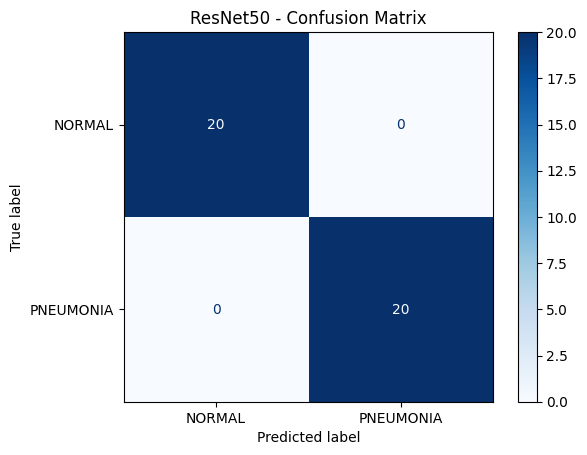

Confusion Matrix:
[[20  0]
 [ 0 20]]


In [48]:

# ==========================================
# 49. CONFUSION MATRIX
# ==========================================

cm = confusion_matrix(y_true, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["NORMAL", "PNEUMONIA"]
)

disp.plot(cmap="Blues", values_format="d")

plt.title("ResNet50 - Confusion Matrix")
plt.show()

print("Confusion Matrix:")
print(cm)


In [49]:

# ==========================================
# 50. CLASSIFICATION REPORT
# ==========================================

print("RESNET50 CLASSIFICATION REPORT")

print(
    classification_report(
        y_true,
        y_pred,
        target_names=["NORMAL", "PNEUMONIA"],
        digits=4
    )
)


RESNET50 CLASSIFICATION REPORT
              precision    recall  f1-score   support

      NORMAL     1.0000    1.0000    1.0000        20
   PNEUMONIA     1.0000    1.0000    1.0000        20

    accuracy                         1.0000        40
   macro avg     1.0000    1.0000    1.0000        40
weighted avg     1.0000    1.0000    1.0000        40



In [50]:

# ==========================================
# 51. TEST DATASET INFORMATION
# ==========================================

print("Total test images:", len(y_test))

print("\nClass distribution:")

for i, name in enumerate(class_names):
    print(name, ":", np.sum(y_test == i))

print("\nCorrect predictions:", np.sum(y_true == y_pred))
print("Incorrect predictions:", np.sum(y_true != y_pred))


Total test images: 40

Class distribution:
NORMAL : 20
PNEUMONIA : 20

Correct predictions: 40
Incorrect predictions: 0


In [51]:

# ==========================================
# 55. CUSTOM CNN MODEL EVALUATION
# ==========================================

cnn_results = cnn_model.evaluate(
    X_test_processed,
    y_test,
    batch_size=16,
    verbose=1
)

print("\nCUSTOM CNN TEST RESULTS")

for name, value in zip(
    cnn_model.metrics_names,
    cnn_results
):
    print(f"{name}: {value:.4f}")


3/3 ━━━━━━━━━━━━━━━━━━━━ 1s 624ms/step - accuracy: 1.0000 - auc: 1.0000 - loss: 0.1637 - precision: 1.0000 - recall: 1.0000

CUSTOM CNN TEST RESULTS
loss: 0.1637
compile_metrics: 1.0000


In [52]:

# ==========================================
# 56. CUSTOM CNN PREDICTIONS
# ==========================================

cnn_pred_prob = cnn_model.predict(X_test_processed)

cnn_pred = (cnn_pred_prob > 0.5).astype(int).flatten()

print("CNN predictions generated successfully!")

print("Actual labels:", y_test[:10])
print("Predicted labels:", cnn_pred[:10])


1/2 ━━━━━━━━━━━━━━━━━━━━ 0s 544ms/step

2/2 ━━━━━━━━━━━━━━━━━━━━ 1s 447ms/step
CNN predictions generated successfully!
Actual labels: [0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
Predicted labels: [0 0 0 0 0 0 0 0 0 0]


In [53]:

# ==========================================
# 56. CUSTOM CNN PREDICTIONS
# ==========================================

cnn_pred_prob = cnn_model.predict(X_test_processed)

cnn_pred = (cnn_pred_prob > 0.5).astype(int).flatten()

print("CNN predictions generated successfully!")

print("Actual labels:", y_test[:10])
print("Predicted labels:", cnn_pred[:10])


2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step
CNN predictions generated successfully!
Actual labels: [0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
Predicted labels: [0 0 0 0 0 0 0 0 0 0]


In [54]:

# ==========================================
# 57. CUSTOM CNN PERFORMANCE METRICS
# ==========================================

cnn_accuracy = accuracy_score(y_true, cnn_pred)

cnn_precision = precision_score(y_true, cnn_pred)
cnn_recall = recall_score(y_true, cnn_pred)
cnn_f1 = f1_score(y_true, cnn_pred)

cnn_auc = roc_auc_score(
    y_true,
    cnn_pred_prob.flatten()
)

print("CUSTOM CNN PERFORMANCE")
print("------------------------")
print(f"Accuracy  : {cnn_accuracy:.4f}")
print(f"Precision : {cnn_precision:.4f}")
print(f"Recall    : {cnn_recall:.4f}")
print(f"F1 Score  : {cnn_f1:.4f}")
print(f"AUC Score : {cnn_auc:.4f}")


CUSTOM CNN PERFORMANCE
------------------------
Accuracy  : 1.0000
Precision : 1.0000
Recall    : 1.0000
F1 Score  : 1.0000
AUC Score : 1.0000


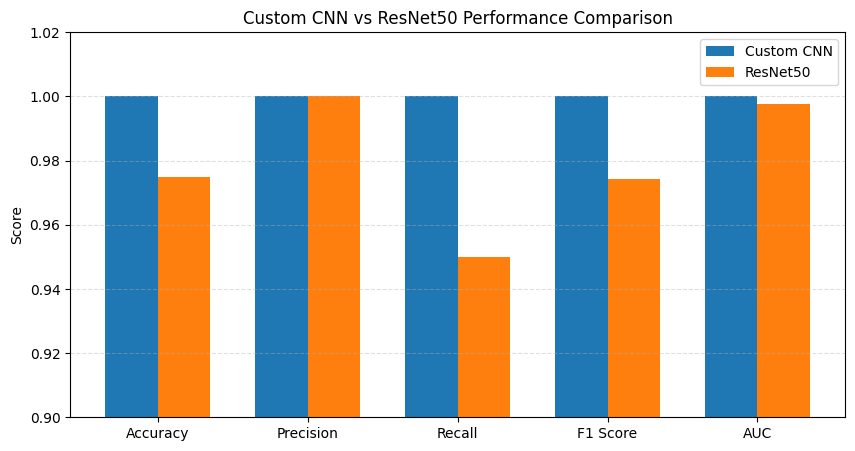

In [55]:
import matplotlib.pyplot as plt
import numpy as np

metrics = ['Accuracy', 'Precision', 'Recall', 'F1 Score', 'AUC']

cnn_scores = [
    cnn_accuracy,
    cnn_precision,
    cnn_recall,
    cnn_f1,
    cnn_auc
]

resnet_scores = [
    0.9750,
    1.0000,
    0.9500,
    0.9744,
    0.9975
]

x = np.arange(len(metrics))
width = 0.35

plt.figure(figsize=(10, 5))

plt.bar(x - width/2, cnn_scores, width, label='Custom CNN')
plt.bar(x + width/2, resnet_scores, width, label='ResNet50')

plt.ylabel('Score')
plt.title('Custom CNN vs ResNet50 Performance Comparison')
plt.xticks(x, metrics)
plt.ylim(0.90, 1.02)
plt.legend()
plt.grid(axis='y', linestyle='--', alpha=0.4)

plt.show()

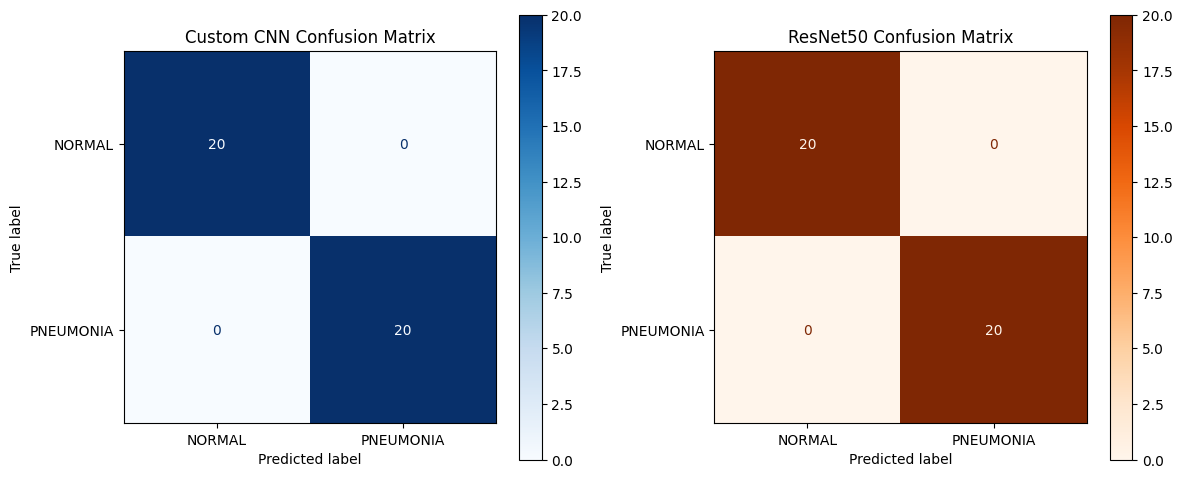

In [56]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Generate confusion matrices
cm_cnn = confusion_matrix(y_true, cnn_pred)
cm_resnet = confusion_matrix(y_true, y_pred)

# Plot side by side
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

ConfusionMatrixDisplay(
    confusion_matrix=cm_cnn,
    display_labels=['NORMAL', 'PNEUMONIA']
).plot(ax=axes[0], cmap='Blues', values_format='d')

axes[0].set_title('Custom CNN Confusion Matrix')

ConfusionMatrixDisplay(
    confusion_matrix=cm_resnet,
    display_labels=['NORMAL', 'PNEUMONIA']
).plot(ax=axes[1], cmap='Oranges', values_format='d')

axes[1].set_title('ResNet50 Confusion Matrix')

plt.tight_layout()
plt.show()

In [57]:
from sklearn.metrics import classification_report

print("========== CUSTOM CNN ==========")
print(classification_report(
    y_true,
    cnn_pred,
    target_names=['NORMAL', 'PNEUMONIA']
))

print("========== RESNET50 ==========")
print(classification_report(
    y_true,
    y_pred,
    target_names=['NORMAL', 'PNEUMONIA']
))

========== CUSTOM CNN ==========
              precision    recall  f1-score   support

      NORMAL       1.00      1.00      1.00        20
   PNEUMONIA       1.00      1.00      1.00        20

    accuracy                           1.00        40
   macro avg       1.00      1.00      1.00        40
weighted avg       1.00      1.00      1.00        40

========== RESNET50 ==========
              precision    recall  f1-score   support

      NORMAL       1.00      1.00      1.00        20
   PNEUMONIA       1.00      1.00      1.00        20

    accuracy                           1.00        40
   macro avg       1.00      1.00      1.00        40
weighted avg       1.00      1.00      1.00        40



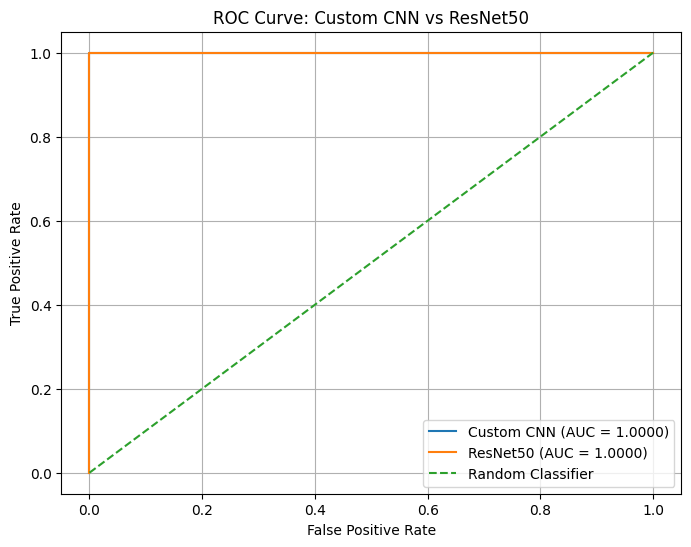

In [58]:
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, auc

# Calculate ROC curves
fpr_cnn, tpr_cnn, _ = roc_curve(
    y_true, cnn_pred_prob.flatten()
)

fpr_resnet, tpr_resnet, _ = roc_curve(
    y_true, y_pred_prob.flatten()
)

auc_cnn = auc(fpr_cnn, tpr_cnn)
auc_resnet = auc(fpr_resnet, tpr_resnet)

# Plot
plt.figure(figsize=(8, 6))

plt.plot(
    fpr_cnn, tpr_cnn,
    label=f'Custom CNN (AUC = {auc_cnn:.4f})'
)

plt.plot(
    fpr_resnet, tpr_resnet,
    label=f'ResNet50 (AUC = {auc_resnet:.4f})'
)

plt.plot([0, 1], [0, 1], linestyle='--', label='Random Classifier')

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve: Custom CNN vs ResNet50')
plt.legend()
plt.grid()
plt.show()

In [59]:
# Saving the best model
cnn_model.save("custom_cnn_model.keras")


print("Model saved successfully!")

Model saved successfully!


In [60]:
# ==========================================
# CUSTOM CNN ARCHITECTURE CHECK
# ==========================================

cnn_model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_3 (Conv2D)               │ (None, 224, 224, 32)   │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 112, 112, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 56, 56, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 327,941 (1.25 MB)

 Trainable params: 109,313 (427.00 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 218,628 (854.02 KB)

Hyperparameter Tuning - Alvin Manoj

In [61]:
!pip install -q keras-tuner

In [62]:
import keras_tuner as kt
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.callbacks import EarlyStopping

In [63]:
def build_tuned_cnn(hp):

    model = models.Sequential()

    # First convolution block
    filters_1 = hp.Choice(
        "filters_1",
        values=[32, 64]
    )

    model.add(
        layers.Conv2D(
            filters=filters_1,
            kernel_size=(3,3),
            activation="relu",
            input_shape=(224,224,1)
        )
    )

    model.add(layers.MaxPooling2D(pool_size=(2,2)))

    # Second convolution block
    filters_2 = hp.Choice(
        "filters_2",
        values=[64, 128]
    )

    model.add(
        layers.Conv2D(
            filters=filters_2,
            kernel_size=(3,3),
            activation="relu"
        )
    )

    model.add(layers.MaxPooling2D(pool_size=(2,2)))

    # Third convolution block
    filters_3 = hp.Choice(
        "filters_3",
        values=[128, 256]
    )

    model.add(
        layers.Conv2D(
            filters=filters_3,
            kernel_size=(3,3),
            activation="relu"
        )
    )

    model.add(layers.MaxPooling2D(pool_size=(2,2)))

    # Global pooling
    model.add(layers.GlobalAveragePooling2D())

    # Dense layer
    dense_units = hp.Choice(
        "dense_units",
        values=[64, 128, 256]
    )

    model.add(
        layers.Dense(
            dense_units,
            activation="relu"
        )
    )

    # Dropout
    dropout_rate = hp.Choice(
        "dropout_rate",
        values=[0.3, 0.4, 0.5]
    )

    model.add(
        layers.Dropout(dropout_rate)
    )

    # Output
    model.add(
        layers.Dense(
            1,
            activation="sigmoid"
        )
    )

    # Learning rate
    learning_rate = hp.Choice(
        "learning_rate",
        values=[1e-4, 5e-4, 1e-3]
    )

    optimizer = tf.keras.optimizers.Adam(
        learning_rate=learning_rate
    )

    model.compile(
        optimizer=optimizer,
        loss="binary_crossentropy",
        metrics=[
            "accuracy",
            tf.keras.metrics.Precision(name="precision"),
            tf.keras.metrics.Recall(name="recall"),
            tf.keras.metrics.AUC(name="auc")
        ]
    )

    return model


In [64]:
tuner = kt.RandomSearch(
    build_tuned_cnn,
    objective=kt.Objective(
        "val_auc",
        direction="max"
    ),
    max_trials=10,
    executions_per_trial=1,
    directory="pneumonia_tuning",
    project_name="custom_cnn"
)

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [65]:
early_stop = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

In [66]:
tuner.search(
    X_train_processed,
    y_train,

    validation_data=(
        X_val_processed,
        y_val
    ),

    epochs=20,

    batch_size=16,

    callbacks=[early_stop]
)

Trial 10 Complete [00h 00m 20s]
val_auc: 0.8999999761581421

Best val_auc So Far: 0.9088889360427856
Total elapsed time: 00h 04m 48s


In [67]:
tuner.results_summary()

Results summary
Results in pneumonia_tuning/custom_cnn
Showing 10 best trials
Objective(name="val_auc", direction="max")

Trial 04 summary
Hyperparameters:
filters_1: 32
filters_2: 128
filters_3: 128
dense_units: 128
dropout_rate: 0.4
learning_rate: 0.0001
Score: 0.9088889360427856

Trial 00 summary
Hyperparameters:
filters_1: 32
filters_2: 128
filters_3: 256
dense_units: 64
dropout_rate: 0.3
learning_rate: 0.0005
Score: 0.8999999761581421

Trial 09 summary
Hyperparameters:
filters_1: 32
filters_2: 64
filters_3: 128
dense_units: 128
dropout_rate: 0.3
learning_rate: 0.0001
Score: 0.8999999761581421

Trial 01 summary
Hyperparameters:
filters_1: 64
filters_2: 128
filters_3: 128
dense_units: 128
dropout_rate: 0.5
learning_rate: 0.0001
Score: 0.8666666746139526

Trial 03 summary
Hyperparameters:
filters_1: 32
filters_2: 64
filters_3: 256
dense_units: 256
dropout_rate: 0.4
learning_rate: 0.0005
Score: 0.8600000143051147

Trial 05 summary
Hyperparameters:
filters_1: 64
filters_2: 64
filters_3

In [68]:
best_hp = tuner.get_best_hyperparameters(
    num_trials=1
)[0]

In [69]:
print("BEST HYPERPARAMETERS")
print("====================")

print("Filters 1:", best_hp.get("filters_1"))
print("Filters 2:", best_hp.get("filters_2"))
print("Filters 3:", best_hp.get("filters_3"))
print("Dense units:", best_hp.get("dense_units"))
print("Dropout:", best_hp.get("dropout_rate"))
print("Learning rate:", best_hp.get("learning_rate"))

BEST HYPERPARAMETERS
Filters 1: 32
Filters 2: 128
Filters 3: 128
Dense units: 128
Dropout: 0.4
Learning rate: 0.0001


In [70]:
best_cnn = tuner.get_best_models(
    num_models=1
)[0]

/usr/local/lib/python3.13/dist-packages/keras/src/saving/saving_lib.py:797: UserWarning: Skipping variable loading for optimizer 'adam', because it has 2 variables whereas the saved optimizer has 22 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))


In [71]:
best_cnn.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 222, 222, 32)   │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 111, 111, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 109, 109, 128)  │        36,992 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 54, 54, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 52, 52, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 26, 26, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 201,537 (787.25 KB)

 Trainable params: 201,537 (787.25 KB)

 Non-trainable params: 0 (0.00 B)

In [72]:
best_history = best_cnn.fit(
    X_train_processed,
    y_train,

    validation_data=(
        X_val_processed,
        y_val
    ),

    epochs=30,

    batch_size=16,

    callbacks=[early_stop]
)

Epoch 1/30
8/8 ━━━━━━━━━━━━━━━━━━━━ 24s 2s/step - accuracy: 0.5593 - auc: 0.5625 - loss: 0.6906 - precision: 0.5614 - recall: 0.5424 - val_accuracy: 0.6333 - val_auc: 0.8311 - val_loss: 0.6850 - val_precision: 0.5833 - val_recall: 0.9333
Epoch 2/30
8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 75ms/step - accuracy: 0.5847 - auc: 0.6425 - loss: 0.6855 - precision: 0.6190 - recall: 0.4407 - val_accuracy: 0.5333 - val_auc: 0.8889 - val_loss: 0.6818 - val_precision: 1.0000 - val_recall: 0.0667
Epoch 3/30
8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 79ms/step - accuracy: 0.5593 - auc: 0.7585 - loss: 0.6817 - precision: 0.8889 - recall: 0.1356 - val_accuracy: 0.5000 - val_auc: 0.8867 - val_loss: 0.6809 - val_precision: 0.0000e+00 - val_recall: 0.0000e+00
Epoch 4/30
8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 102ms/step - accuracy: 0.6780 - auc: 0.7620 - loss: 0.6771 - precision: 0.8000 - recall: 0.4746 - val_accuracy: 0.8000 - val_auc: 0.8644 - val_loss: 0.6819 - val_precision: 0.9091 - val_recall: 0.6667
Epoch 5/30
8/8 ━━━━━━━━━━━━━━━━━━━━ 

In [ ]:
plt.figure(figsize=(8, 5))

plt.plot(
    best_history.history["accuracy"],
    label="Training Accuracy"
)

plt.plot(
    best_history.history["val_accuracy"],
    label="Validation Accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Hyperparameter Tuned CNN Accuracy")

plt.legend()
plt.show()

In [73]:
best_cnn.save("hyperparameter_tuned_cnn.keras")
print("Tuned CNN model saved successfully.")

In [74]:
test_image_paths = []
test_labels = []

class_names = ["NORMAL", "PNEUMONIA"]

for label, class_name in enumerate(class_names):

    folder = os.path.join(
        dataset_path,
        "test",
        class_name
    )

    for filename in os.listdir(folder):

        if filename.lower().endswith(
            (".jpg", ".jpeg", ".png")
        ):

            test_image_paths.append(
                os.path.join(folder, filename)
            )

            test_labels.append(label)

In [75]:
X_test_processed = preprocess_images(
    test_image_paths
)

y_test = np.array(
    test_labels,
    dtype=np.float32
)

print("Test shape:", X_test_processed.shape)
print("Test labels:", y_test.shape)

Test shape: (40, 224, 224, 1)
Test labels: (40,)


In [76]:
test_results = best_cnn.evaluate(
    X_test_processed,
    y_test,
    verbose=1
)

2/2 ━━━━━━━━━━━━━━━━━━━━ 8s 3s/step - accuracy: 1.0000 - auc: 1.0000 - loss: 0.5361 - precision: 1.0000 - recall: 1.0000


In [77]:
print("\nFINAL TEST RESULTS")
print("==================")

print("Test Loss      :", test_results[0])
print("Test Accuracy  :", test_results[1])
print("Test Precision :", test_results[2])
print("Test Recall    :", test_results[3])
print("Test AUC       :", test_results[4])


FINAL TEST RESULTS
Test Loss      : 0.5360763669013977
Test Accuracy  : 1.0
Test Precision : 1.0
Test Recall    : 1.0
Test AUC       : 1.0


In [78]:
#Calculate F1 score
from sklearn.metrics import f1_score

y_pred_prob = best_cnn.predict(
    X_test_processed
)

y_pred = (y_pred_prob >= 0.5).astype(int).flatten()

f1 = f1_score(
    y_test,
    y_pred
)

print("Test F1 Score :", f1)

2/2 ━━━━━━━━━━━━━━━━━━━━ 1s 490ms/step
Test F1 Score : 1.0


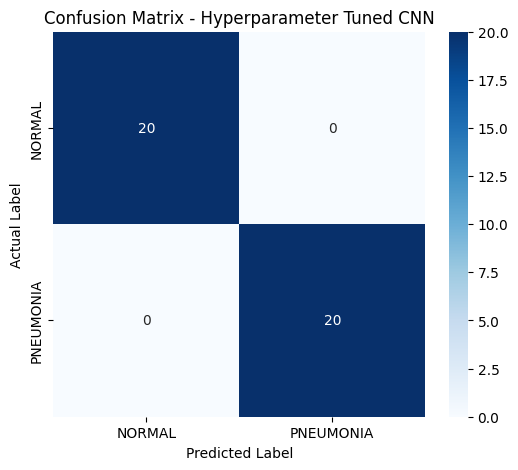

In [79]:
# Confusion matrix
from sklearn.metrics import confusion_matrix
import seaborn as sns

cm = confusion_matrix(
    y_test,
    y_pred
)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["NORMAL", "PNEUMONIA"],
    yticklabels=["NORMAL", "PNEUMONIA"]
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("Confusion Matrix - Hyperparameter Tuned CNN")

plt.show()

In [ ]:
# Classification report
from sklearn.metrics import classification_report

print(
    classification_report(
        y_test,
        y_pred,
        target_names=[
            "NORMAL",
            "PNEUMONIA"
        ]
    )
)

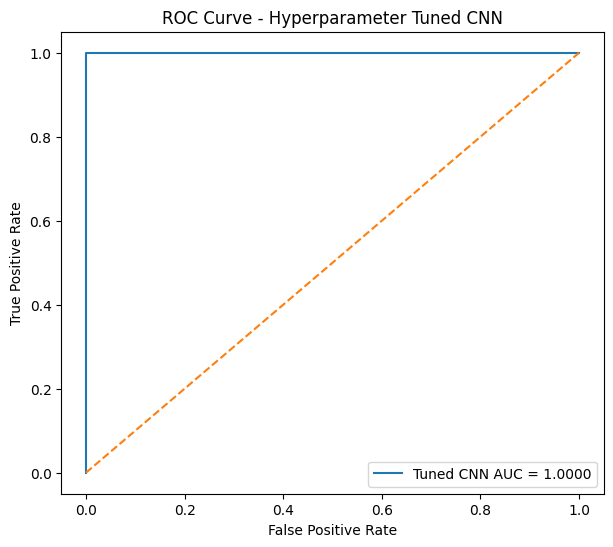

In [80]:
from sklearn.metrics import roc_curve, roc_auc_score

fpr, tpr, thresholds = roc_curve(
    y_test,
    y_pred_prob
)

auc_score = roc_auc_score(
    y_test,
    y_pred_prob
)

plt.figure(figsize=(7, 6))

plt.plot(
    fpr,
    tpr,
    label=f"Tuned CNN AUC = {auc_score:.4f}"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")

plt.title("ROC Curve - Hyperparameter Tuned CNN")

plt.legend()

plt.show()